In [14]:
## AI Firewall for Threat Detection and Automated Response

## This project uses the UNSW-NB15 dataset with a Random Forest model to classify network traffic as normal or malicious.
## If there is malicious traffic detected, the system will recommend blocking the traffic

In [15]:
## Import Libraries
## Load all libraries needed for data analysis, machine learning, and visualization.
## Load all libraries for data analysis, machine learning, and visualization

# Libraries for data handling
import pandas as pd
import numpy as np

# ML models and evaluation tools
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Libraries for charts and visuals
import seaborn as sns
import matplotlib.pyplot as plt


In [16]:
## Load Dataset

## Import the UNSW-NB15 training and testing datasets

# Loading the training and testing datasets
train_data = pd.read_csv("UNSW_NB15_training-set.csv")
test_data = pd.read_csv("UNSW_NB15_testing-set.csv")

# Display the dataset size
print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

train_data.head()

Training data shape: (82332, 45)
Testing data shape: (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [17]:
## Review Dataset Columns
## Check available columns and identify the target label.

# Showing all column names in training dataset
train_data.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')

In [18]:

## Prepare Features and Labels
## Separate input features from the target and remove data leakage.

# Remove the target, attack category, and dataset identifier
train_features = train_data.drop(columns=["label", "attack_cat", "id"])
train_labels = train_data["label"]

test_features = test_data.drop(columns=["label", "attack_cat", "id"])
test_labels = test_data["label"]

# Display the shapes after splitting the data
print("Training features shape:", train_features.shape)
print("Training labels shape:", train_labels.shape)
print("Testing features shape:", test_features.shape)
print("Testing labels shape:", test_labels.shape)



Training features shape: (82332, 42)
Training labels shape: (82332,)
Testing features shape: (175341, 42)
Testing labels shape: (175341,)


In [19]:
## Encode Categorical Data
## Convert text-based columns into numeric values so model can process.

# Convert the text based columns into numeric values
train_features = pd.get_dummies(train_features)
test_features = pd.get_dummies(test_features)

# Make sure that both datasets match columns
train_features, test_features = train_features.align(
    test_features, join="left", axis=1, fill_value=0
)

# Display the shapes after encoding
print("Encoded training features shape:", train_features.shape)
print("Encoded testing features shape:", test_features.shape)


Encoded training features shape: (82332, 190)
Encoded testing features shape: (175341, 190)


In [20]:
## Train Random Forest Model
## Train the classifier to learn patterns of what is normal and malicious traffic.

# Create the Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using the training dataset
rf_model.fit(train_features, train_labels)

print("training complete.")


training complete.


In [21]:
## Make Predictions
## Use the trained model to classify unseen network traffic.

# Use the trained model to predict traffic labels
predictions = rf_model.predict(test_features)

print("predictions complete.")



predictions complete.


In [22]:

## Evaluate Performance
## Measure model accuracy and classification performance.

# Measure the models performance on testing data
accuracy = accuracy_score(test_labels, predictions)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(
    test_labels,
    predictions,
    target_names=["Normal", "Malicious"]
))



Accuracy: 0.9043349815502364

Classification Report:
              precision    recall  f1-score   support

      Normal       0.78      0.98      0.87     56000
   Malicious       0.99      0.87      0.93    119341

    accuracy                           0.90    175341
   macro avg       0.88      0.92      0.90    175341
weighted avg       0.92      0.90      0.91    175341



In [23]:
## Simulate Firewall Response
## Recommend allowing or blocking traffic based on predictions.

# Create a table showing predictions and firewall actions
firewall_results = pd.DataFrame({
    "Actual": test_labels,
    "Predicted": predictions
})

# Simulate firewall response based on prediction
firewall_results["Response"] = firewall_results["Predicted"].apply(
    lambda traffic_label: "BLOCK TRAFFIC" if traffic_label == 1 else "ALLOW TRAFFIC"
)

# Show first 10 results
firewall_results.head(10)



,Actual,Predicted,Response
0,0,1,BLOCK TRAFFIC
1,0,1,BLOCK TRAFFIC
2,0,1,BLOCK TRAFFIC
3,0,1,BLOCK TRAFFIC
4,0,0,ALLOW TRAFFIC
5,0,0,ALLOW TRAFFIC
6,0,0,ALLOW TRAFFIC
7,0,0,ALLOW TRAFFIC
8,0,0,ALLOW TRAFFIC
9,0,0,ALLOW TRAFFIC


In [24]:
## Response Summary
## Count how many times the system recommended each action.

# Count how many times each firewall action was recommended
firewall_results["Response"].value_counts()


,count
Response,
BLOCK TRAFFIC,105127
ALLOW TRAFFIC,70214


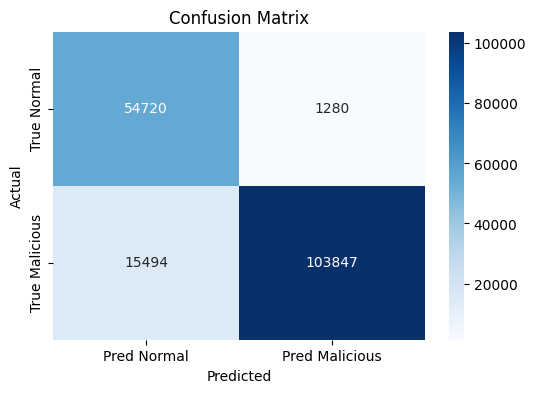

In [25]:
## Confusion Matrix
## Visualize correct and incorrect predictions.

# Build confusion matrix to compare actual vs predicted results
conf_matrix = confusion_matrix(test_labels, predictions)

# Display heatmap of model performance
plt.figure(figsize=(6, 4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Normal", "Pred Malicious"],
    yticklabels=["True Normal", "True Malicious"]
)

plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


In [26]:
## Feature Importance
## Show which network traffic features influenced the model most.

# Show which features had the biggest impact on predictions
feature_scores = pd.Series(
    rf_model.feature_importances_,
    index=train_features.columns
)

# Sort from highest importance to lowest
feature_scores = feature_scores.sort_values(ascending=False)

# Display top 10 most important features
feature_scores.head(10)

,0
ct_dst_src_ltm,0.074100
sttl,0.061689
sload,0.058677
sbytes,0.053775
smean,0.044472
ct_srv_dst,0.042911
ct_state_ttl,0.042448
ct_dst_sport_ltm,0.041918
rate,0.041508
dbytes,0.036344
